In [1]:
from base.environment import Environment
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Graphs Thesis

In [2]:
SIMU = Environment(N=10, Lambda=0, p = 0.5, seed = 1)

In [3]:
from datetime import datetime

import networkx as nx
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

def graph(self, save = False, selected_node=None):
    COLOR_PATIENT = "#4A90E2"
    COLOR_IMPATIENT = "#D9534F"
    COLOR_EDGE = "#BDC3C7"

    patient_nodes = []
    impatient_nodes = []

    for node in self.G.nodes():
        agent = self.agents_by_node[node]

        if agent.is_patient:
            patient_nodes.append(node)
        else:
            impatient_nodes.append(node)


    if self.network_type == "grid":
        self.pos = {node: node for node in self.G.nodes()}
    elif self.network_type == "clustered":
        self.pos = nx.spring_layout(self.G, k=0.15, iterations=100, seed=42)
    else:
        self.pos = nx.spring_layout(self.G, seed=42)

    fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
    
    nx.draw_networkx_edges(self.G, self.pos, ax=ax, edge_color=COLOR_EDGE, style="dashed", width=1.5, alpha=0.8)
    nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=patient_nodes, node_color=COLOR_PATIENT, edgecolors="#2C3E50", node_size=380, linewidths=1.2)
    nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=impatient_nodes, node_color=COLOR_IMPATIENT, edgecolors="#5B1208", node_size=380, linewidths=1.2)

    if self.network_type == "grid":
        labels = {node: i for i, node in enumerate(self.G.nodes())}
        nx.draw_networkx_labels(self.G, self.pos, ax=ax, labels=labels, font_size=11, font_color="white", font_weight="bold")
    else:
        nx.draw_networkx_labels(self.G, self.pos, ax=ax, font_size=11, font_color="white", font_weight="bold")

    
    ax.set_title("Depositor Interaction Network Topology", loc="left", fontweight="bold", pad=20, fontsize=18)
    if self.network_type == 'clustered':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($C = $ {self.number_of_clusters}, $p_i =$ {self.p_inside}, $p_o =$ {self.p_outside})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    elif self.network_type == 'grid':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ({int(self.N**0.5)}x{int(self.N**0.5)})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    elif self.network_type == 'Watts-Strogatz':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($p = $ {self.p}, $k = $ {self.mean_degree_par})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    elif self.network_type == 'Barabasi-Albert':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($m = $ {self.edges_par})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    else:
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($p = $ {self.p})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")

    if selected_node is not None:
        nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=[selected_node], node_color= COLOR_IMPATIENT, edgecolors="black", node_size=500, linewidths=2.5)

        # Conexiones incidentes al nodo seleccionado
        selected_edges = [(u, v) for u, v in self.G.edges() if u == selected_node or v == selected_node]

        nx.draw_networkx_edges(self.G, self.pos, ax=ax, edgelist=selected_edges, edge_color="#2C3E50", style="solid", width=2.8, alpha=1.0)

    ax.axis("off")
    ax.set_aspect("equal")

    legend_handles = [mpatches.Patch(color=COLOR_PATIENT, ec="#2C3E50", label=r"Depositors"), mlines.Line2D([], [], color=COLOR_EDGE, lw=1.8, ls="--", label=r"Interaction Channels ($g_{ij}$)"), mpatches.Patch(color=COLOR_IMPATIENT, ec="#5B1208", label=r"Selected Depositor"), mlines.Line2D([], [], color='#2C3E50', lw=2.8, label=r"Local Neighborhood ($\mathcal {N} _{4}$)")]

    ax.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=False, fontsize=13, labelspacing=1.2, handlelength=2.2, handleheight=1.5)
    
    plt.tight_layout()
    if save:
        plt.savefig(f'outputs/MODEL/FIG{datetime.now().strftime("%d-%m-%y.%H.%M.%S")}.png', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


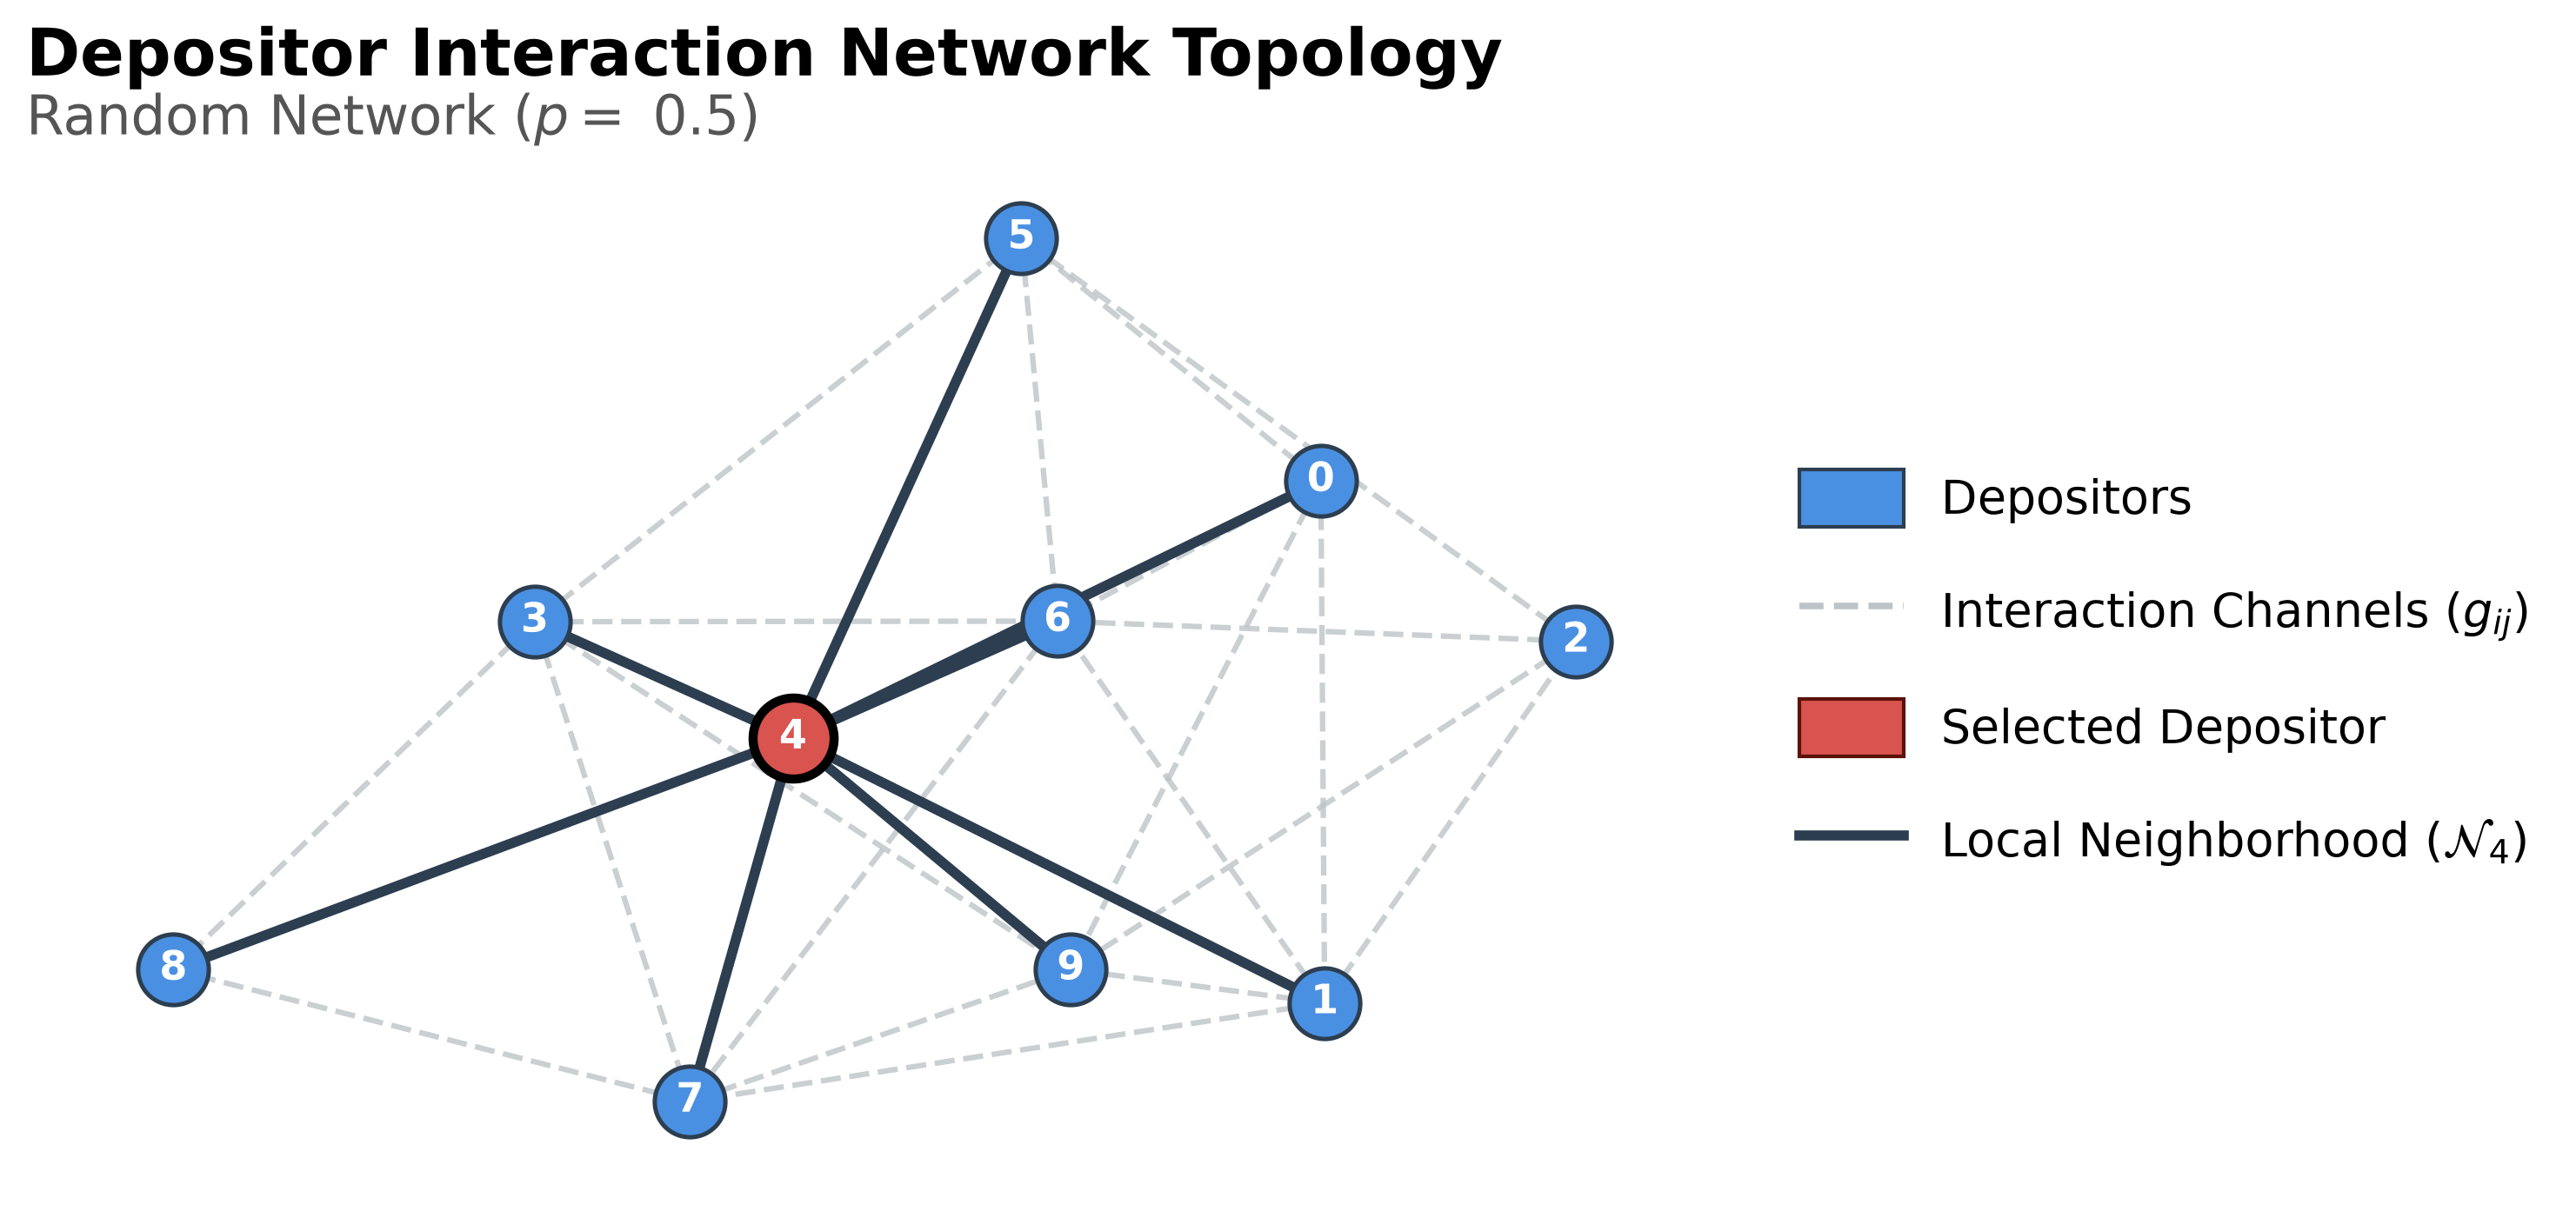

In [4]:
graph(SIMU.network, selected_node=4)

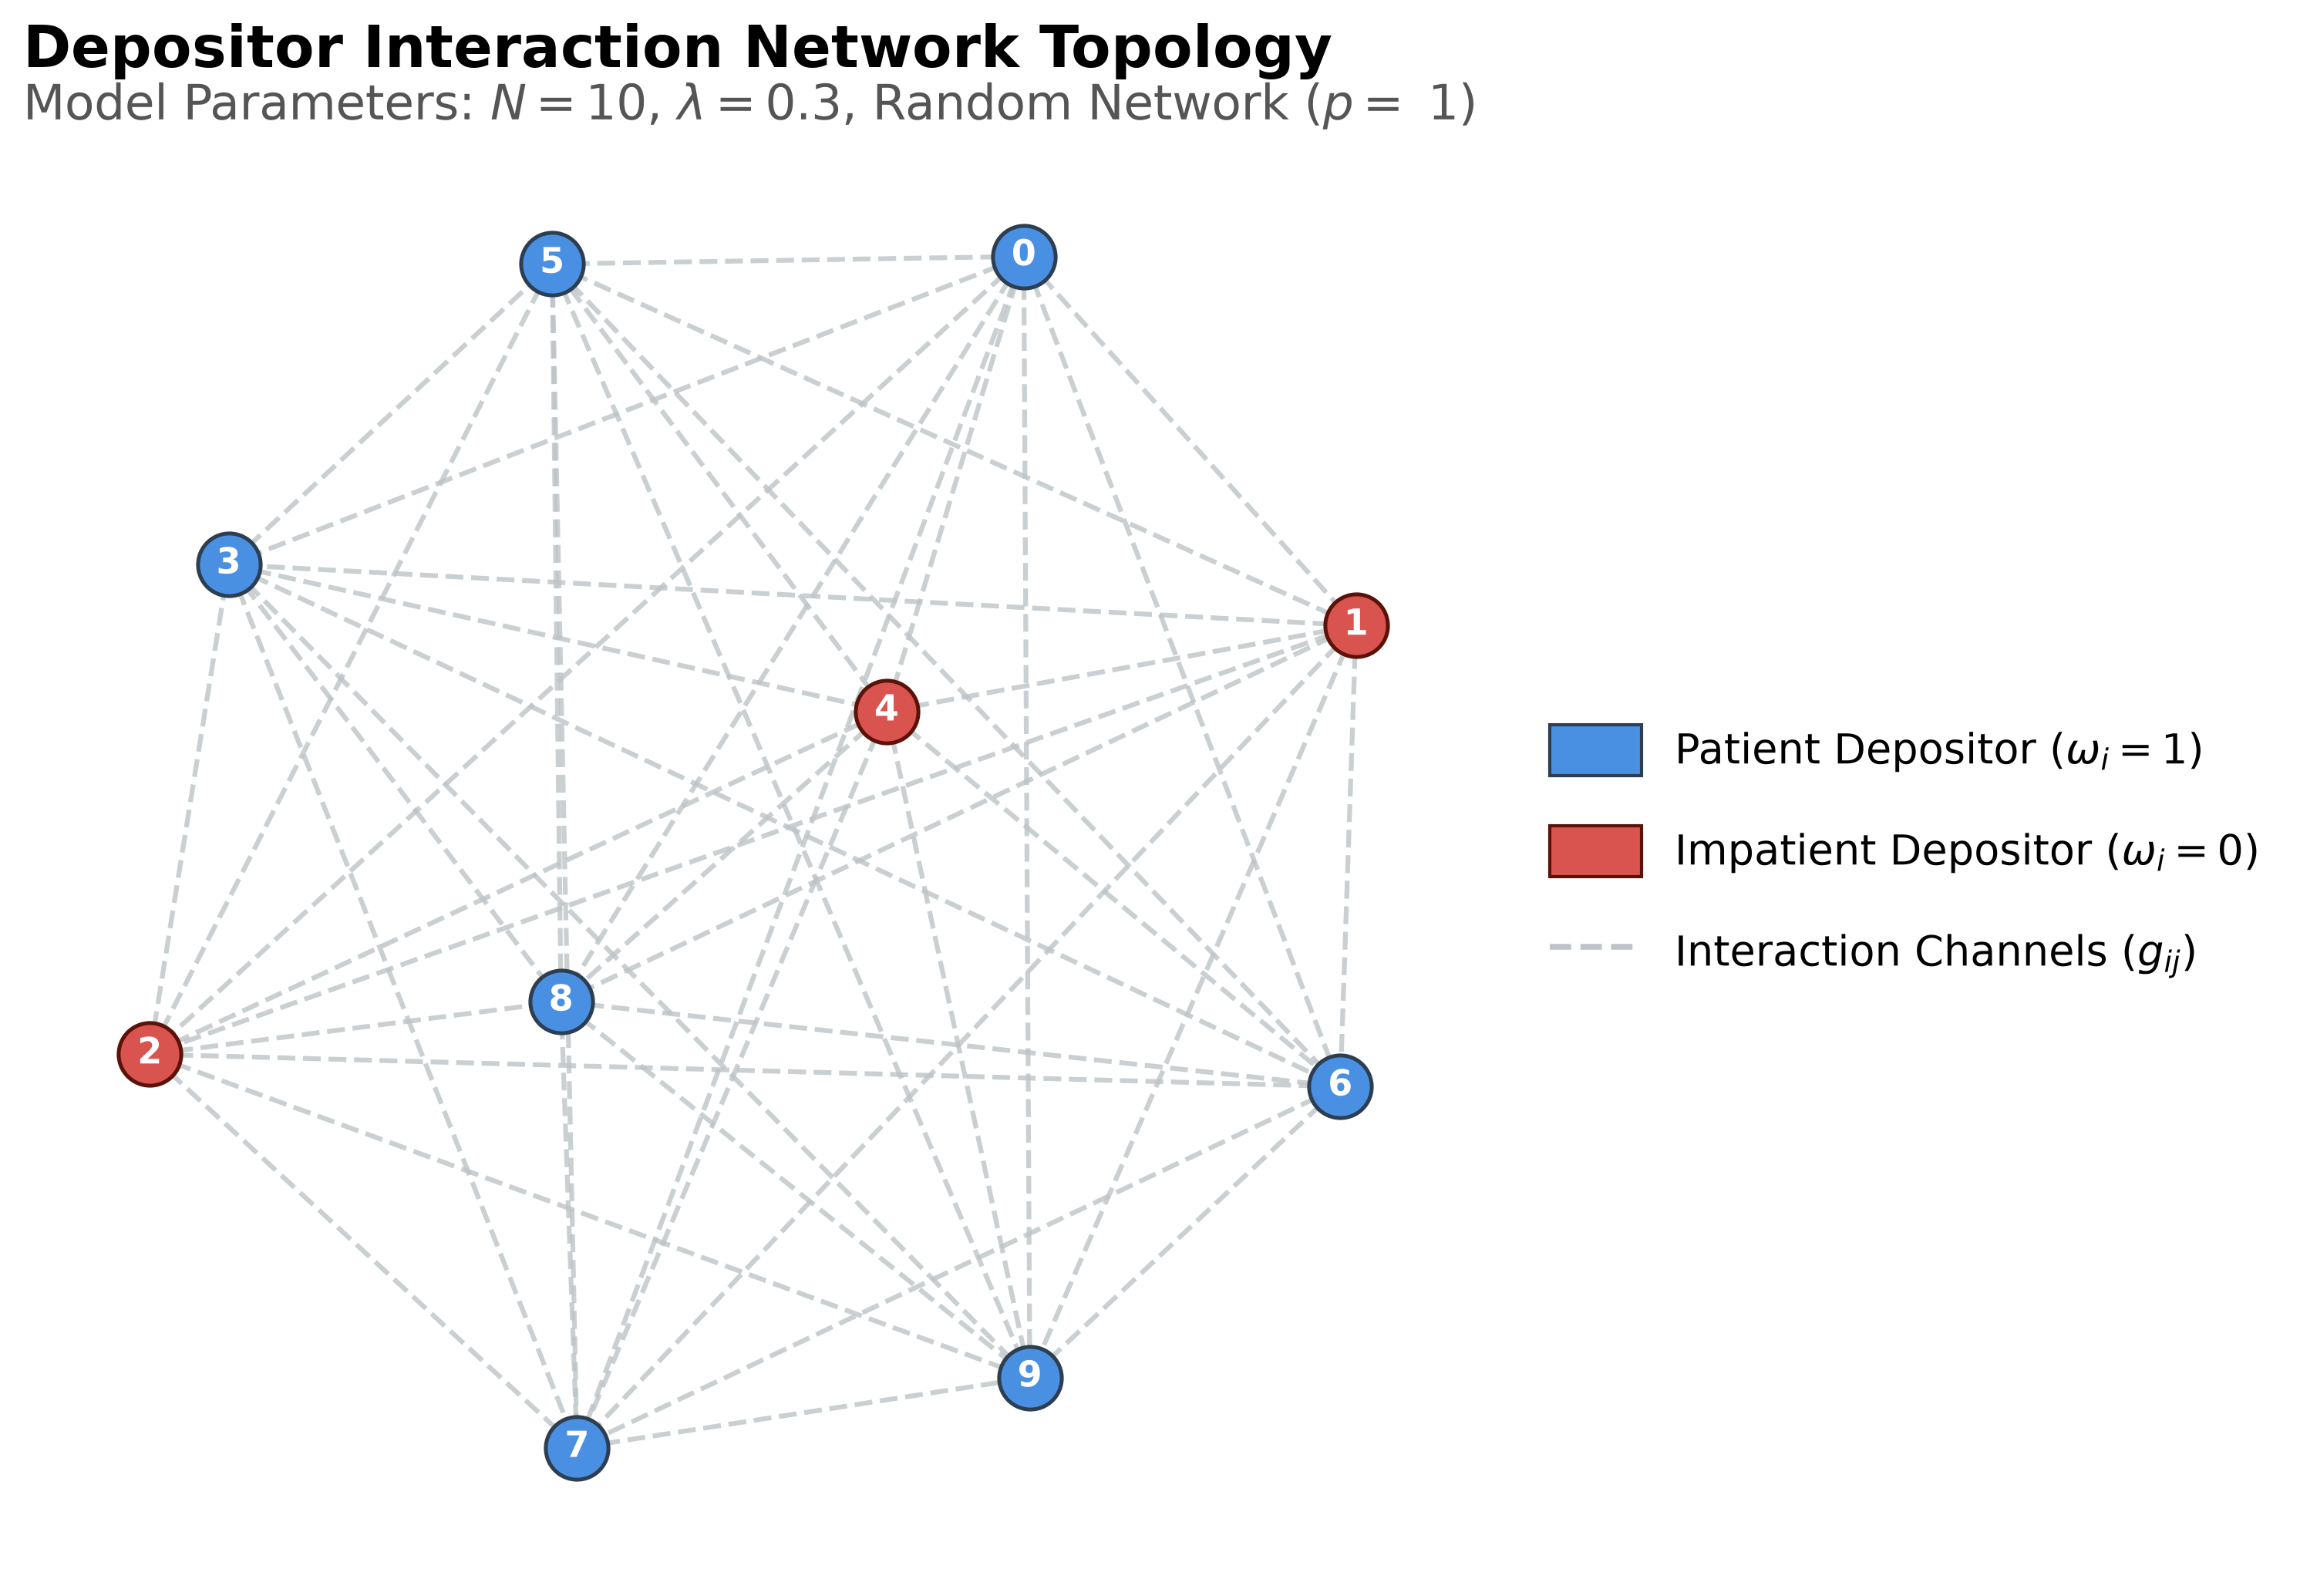

In [5]:
SIMU = Environment(N=10, Lambda=0.3, p = 1, seed = 1)
SIMU.network.graph()

In [ ]:
import random


N_values = [50, 100]
Lambda_values = [0.1,0.2] # small shocks
p_values = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

results = []

random.seed(1)
np.random.seed(1)

for N in N_values:
    for Lambda in Lambda_values:
        for p in p_values:
                print(N, Lambda, p)
                for simulation_id in range(500):
                    SIMU = Environment(N=N, Lambda=Lambda, network_type='random', p=p, liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta=1, R=1.5, r=1.28)
                    SIMU.simulation(printing=False)
            
                    results.append({
                        'N': N,
                        'lambda': Lambda,
                        'Mean_Degree': SIMU.network.mean_degree(),
                        'Density': SIMU.network.density(),
                        'Average_Path_Length': SIMU.network.average_path_length(),
                        'Average_Clustering': SIMU.network.average_clustering(),
                        'Clustering': SIMU.network.clustering(),
                        'p': p,
                        'simulation': simulation_id,
                        'bank_failure': SIMU.bank_failure,
                        'run_percentage': SIMU.run_percentage
                    })

df_results = pd.DataFrame(results)
with open('outputs/SIMULATIONS/VALUES_RANDOM.txt', 'w') as f:
    df_string = df_results.to_string(index=False)
    f.write(df_string)

dfRANDOM = pd.read_fwf('outputs/SIMULATIONS/VALUES_RANDOM.txt')
dfRANDOM['density_bin'] = (dfRANDOM['Density'] * 100).round() / 100
dfRANDOM.head()


50 0.1 0
50 0.1 0.1
50 0.1 0.2
50 0.1 0.3
50 0.1 0.4
50 0.1 0.5
50 0.1 0.6
50 0.1 0.7
50 0.1 0.8
50 0.1 0.9
50 0.1 1
50 0.2 0
50 0.2 0.1
50 0.2 0.2
50 0.2 0.3
50 0.2 0.4
50 0.2 0.5
50 0.2 0.6
50 0.2 0.7
50 0.2 0.8
50 0.2 0.9
50 0.2 1
100 0.1 0
100 0.1 0.1
100 0.1 0.2
100 0.1 0.3
100 0.1 0.4
100 0.1 0.5
100 0.1 0.6
100 0.1 0.7
100 0.1 0.8
100 0.1 0.9
100 0.1 1
100 0.2 0
100 0.2 0.1
100 0.2 0.2
100 0.2 0.3
100 0.2 0.4
100 0.2 0.5
100 0.2 0.6
100 0.2 0.7
100 0.2 0.8
100 0.2 0.9
100 0.2 1


,N,lambda,Mean_Degree,Density,Average_Path_Length,Average_Clustering,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 98,Unnamed: 99,Unnamed: 100,Unnamed: 101,Clustering,p,simulation,bank_failure,run_percentage,density_bin
0,50,0.1,0.0,0.0,0.0,0.0,{0:,"0,",1:,"0,",...,46:,"0,",47:,"0,","48: 0, 49: 0}",0.0,0,False,0.1,0.0
1,50,0.1,0.0,0.0,0.0,0.0,{0:,"0,",1:,"0,",...,46:,"0,",47:,"0,","48: 0, 49: 0}",0.0,1,False,0.1,0.0
2,50,0.1,0.0,0.0,0.0,0.0,{0:,"0,",1:,"0,",...,46:,"0,",47:,"0,","48: 0, 49: 0}",0.0,2,False,0.1,0.0
3,50,0.1,0.0,0.0,0.0,0.0,{0:,"0,",1:,"0,",...,46:,"0,",47:,"0,","48: 0, 49: 0}",0.0,3,False,0.1,0.0
4,50,0.1,0.0,0.0,0.0,0.0,{0:,"0,",1:,"0,",...,46:,"0,",47:,"0,","48: 0, 49: 0}",0.0,4,False,0.1,0.0


In [ ]:
p_values = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
mean_degree_values = [1, 2,4,6,8,10,12,14,16,18,20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]


results = []

random.seed(1)
np.random.seed(1)

for N in N_values:
    for Lambda in Lambda_values:
        for p in p_values:
            for mean_degree in mean_degree_values:
                if N >= mean_degree:
                    print(N, Lambda, p, mean_degree)
                    for simulation_id in range(1000):
                        SIMU = Environment(N=N, Lambda=Lambda, network_type='WS', p=p, mean_degree=mean_degree, liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta=1, R=1.5, r=1.28)
                        SIMU.simulation(printing=False)
                
                        results.append({
                            'N': N,
                            'lambda': Lambda,
                            'Mean_Degree': SIMU.network.mean_degree(),
                            'Density': SIMU.network.density(),
                            'Average_Path_Length': SIMU.network.average_path_length(),
                            'Average_Clustering': SIMU.network.average_clustering(),
                            'Clustering': SIMU.network.clustering(),
                            'p': p,
                            'simulation': simulation_id,
                            'bank_failure': SIMU.bank_failure,
                            'run_percentage': SIMU.run_percentage
                        })

df_results = pd.DataFrame(results)
with open('outputs/SIMULATIONS/VALUES_WS.txt', 'w') as f:
    df_string = df_results.to_string(index=False)
    f.write(df_string)

dfWS = pd.read_fwf('outputs/SIMULATIONS/VALUES_WS.txt')
dfWS['density_bin'] = (dfWS['Density'] * 100).round() / 100
dfWS.head()

50 0.1 0 1
50 0.1 0 2
50 0.1 0 4
50 0.1 0 6
50 0.1 0 8
50 0.1 0 10
50 0.1 0 12
50 0.1 0 14
50 0.1 0 16
50 0.1 0 18
50 0.1 0 20
50 0.1 0 25
50 0.1 0 30
50 0.1 0 35
50 0.1 0 40
50 0.1 0 45
50 0.1 0 50
50 0.1 0.1 1
50 0.1 0.1 2
50 0.1 0.1 4
50 0.1 0.1 6
50 0.1 0.1 8
50 0.1 0.1 10
50 0.1 0.1 12
50 0.1 0.1 14
50 0.1 0.1 16
50 0.1 0.1 18
50 0.1 0.1 20
50 0.1 0.1 25
50 0.1 0.1 30
50 0.1 0.1 35
50 0.1 0.1 40
50 0.1 0.1 45
50 0.1 0.1 50
50 0.1 0.2 1
50 0.1 0.2 2
50 0.1 0.2 4
50 0.1 0.2 6
50 0.1 0.2 8
50 0.1 0.2 10
50 0.1 0.2 12
50 0.1 0.2 14
50 0.1 0.2 16
50 0.1 0.2 18
50 0.1 0.2 20
50 0.1 0.2 25
50 0.1 0.2 30
50 0.1 0.2 35
50 0.1 0.2 40
50 0.1 0.2 45
50 0.1 0.2 50
50 0.1 0.3 1
50 0.1 0.3 2
50 0.1 0.3 4
50 0.1 0.3 6
50 0.1 0.3 8
50 0.1 0.3 10
50 0.1 0.3 12
50 0.1 0.3 14
50 0.1 0.3 16
50 0.1 0.3 18
50 0.1 0.3 20
50 0.1 0.3 25
50 0.1 0.3 30
50 0.1 0.3 35
50 0.1 0.3 40
50 0.1 0.3 45
50 0.1 0.3 50
50 0.1 0.4 1
50 0.1 0.4 2
50 0.1 0.4 4
50 0.1 0.4 6
50 0.1 0.4 8
50 0.1 0.4 10
50 0.1 0.4 12
50 0.1 0.

In [ ]:
edges_values = [1,2,3,4,5,6,7,8,9,10, 15, 20, 25, 30, 35, 40, 45, 49, 55, 60, 65, 70, 75, 80, 85, 90, 95, 99]


results = []

random.seed(1)
np.random.seed(1)

for N in N_values:
    for Lambda in Lambda_values:
        for edges in edges_values:
            if N > edges:
                print(N, Lambda, edges)
                for simulation_id in range(1000):
                    SIMU = Environment(N=N, Lambda=Lambda, network_type='BA', edges=edges, liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta=1, R=1.5, r=1.28)
                    SIMU.simulation(printing=False)
            
                    results.append({
                        'N': N,
                        'lambda': Lambda,
                        'Mean_Degree': SIMU.network.mean_degree(),
                        'Density': SIMU.network.density(),
                        'Average_Path_Length': SIMU.network.average_path_length(),
                        'Average_Clustering': SIMU.network.average_clustering(),
                        'Clustering': SIMU.network.clustering(),
                        'edges': edges,
                        'simulation': simulation_id,
                        'bank_failure': SIMU.bank_failure,
                        'run_percentage': SIMU.run_percentage
                    })

df_results = pd.DataFrame(results)
with open('outputs/SIMULATIONS/VALUES_BA.txt', 'w') as f:
    df_string = df_results.to_string(index=False)
    f.write(df_string)

dfBA = pd.read_fwf('outputs/SIMULATIONS/VALUES_BA.txt')
dfBA['density_bin'] = (dfBA['Density'] * 100).round() / 100
dfBA.head()